# Denna notebook redogör för statistisk analys av hälsodata inför examinerande inlämningsuppgift.
Del 1 går igenom en utforskande analys av datans innehåll, datatyper och fördelning. Del 2 går sedan vidare och ser på mönster och eventuella samband i datan.

#### Vi börjar med att importera de bibliotek som analysen kommer att kräva.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from health_analyzer import HealthAnalyzer

#### Sedan läser vi in datan

Datasetet läses in från en CSV-fil med pandas `read_csv`.
De första fem raderna visas med `head()` för en första kontroll
av inläsningen.

Dokumentation:
- [pandas.read_csv](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)
- [DataFrame.head](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html)

In [2]:
df = pd.read_csv("health_study_dataset.csv")
df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


### Kontroll av datastruktur

Med `info()` granskas kolumnnamn, datatyper och antalet
icke-saknade värden per kolumn. Detta används för att kontrollera
datastrukturen inför analysen.

Dokumentation:
- [DataFrame.info](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.info.html)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


### Beskrivande statistik

Medelvärde, median, minimum och maximum beräknas för age,
weight, height, systolic_bp och cholesterol. Metoden `agg()`
används för att tillämpa flera sammanfattningsfunktioner på
de valda kolumnerna.

Dokumentation:
- [DataFrame.agg](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.agg.html)

In [4]:
variables = ["age", "weight", "height", "systolic_bp", "cholesterol"]

analyzer = HealthAnalyzer(df)

summary = analyzer.descriptive_statistics(variables)

summary.round(2)

,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


#### Datasetet omfattar 800 personer. Medelåldern är 49,43 år och medianåldern 50 år. För samtliga fem variabler ligger medelvärdet nära medianen. Systoliskt blodtryck har ett medelvärde på 149,18 och varierar mellan 106,80 och 185,90.

** värdera att radera denna text, alternativt kraftigt redigera den **

### Fördelning av systoliskt blodtryck

Ett histogram används för att undersöka blodtryckets fördelning,
spridning och eventuell asymmetri. Med seaborns `histplot()`
delas värdena in i 25 intervall (`bins=25`), där staplarnas höjd
visar antalet personer i respektive intervall. Antalet intervall
är ett presentationsval som påverkar hur detaljerad grafen blir.

Dokumentation:
- [seaborn.histplot](https://seaborn.pydata.org/generated/seaborn.histplot.html)

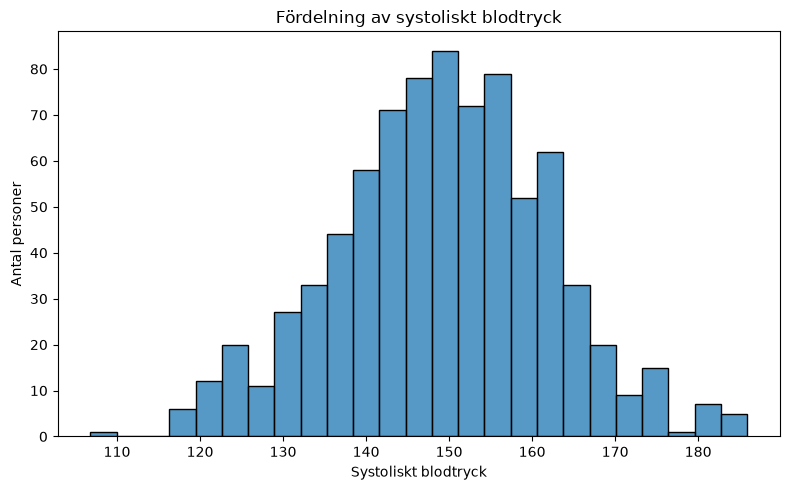

In [5]:
analyzer.plot_histogram(
    column="systolic_bp",
    title="Fördelning av systoliskt blodtryck",
    xlabel="Systoliskt blodtryck"
)

### Viktfördelning per kön

En boxplot används för att jämföra viktens median och spridning
mellan könsgrupperna. Lådan sträcker sig från första till tredje
kvartilen och innehåller därmed de mittersta 50 procenten av
värdena. Linjen i lådan visar medianen.

Med standardinställningen sträcker sig morrhåren till de yttersta
observationerna inom 1,5 gånger kvartilavståndet från lådans
kanter. Värden utanför dessa gränser visas som separata punkter.
De är potentiella extremvärden, men inte automatiskt felaktiga.

Dokumentation:
- [seaborn.boxplot](https://seaborn.pydata.org/generated/seaborn.boxplot.html)

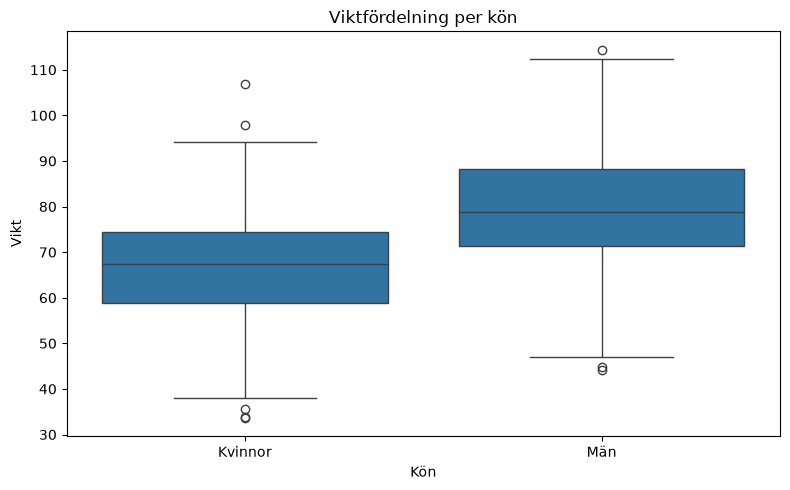

In [6]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="sex", y="weight", order=["F", "M"])

plt.title("Viktfördelning per kön")
plt.xlabel("Kön")
plt.ylabel("Vikt")
plt.xticks([0, 1], ["Kvinnor", "Män"])

plt.tight_layout()
plt.show()

#### Män har högre medianvikt än kvinnor i datasetet, men fördelningarna överlappar. Spridningen bland de mittersta 50 procenten är något större för män. Båda grupperna har potentiella extremvärden.

** värdera att radera denna text, alternativt kraftigt redigera den **

### Andel rökare och icke-rökare

Ett stapeldiagram används för att jämföra andelen personer i
de två rökkategorierna. Med `value_counts(normalize=True)`
beräknas relativa frekvenser, som multipliceras med 100 för
att uttryckas i procent. `reindex()` bestämmer kategoriernas
ordning och `plot(kind="bar")` skapar stapeldiagrammet.

Y-axeln visas från 0 till 100 procent för att tydliggöra
gruppernas andelar av datasetet.

Dokumentation:
- [Series.value_counts](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html)
- [Series.reindex](https://pandas.pydata.org/docs/reference/api/pandas.Series.reindex.html)
- [Series.plot.bar](https://pandas.pydata.org/docs/reference/api/pandas.Series.plot.bar.html)

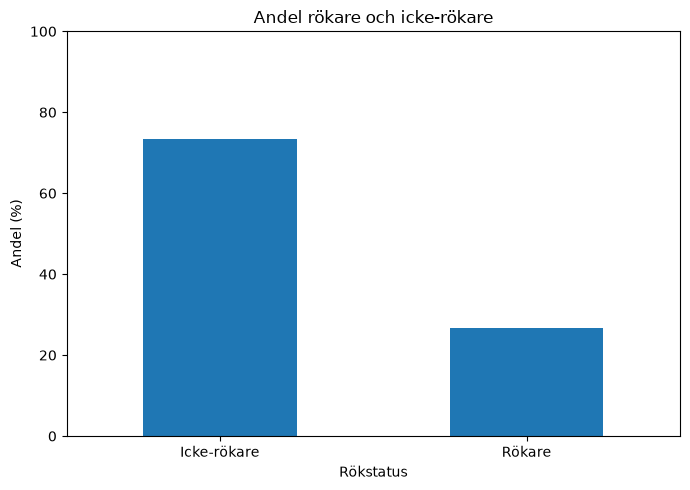

smoker
No     73.4
Yes    26.6
Name: proportion, dtype: float64


In [7]:
smoker_percent = (
    df["smoker"]
    .value_counts(normalize=True)
    .reindex(["No", "Yes"]) * 100
)

plt.figure(figsize=(7, 5))

smoker_percent.plot(kind="bar", rot=0)

plt.title("Andel rökare och icke-rökare")
plt.xlabel("Rökstatus")
plt.ylabel("Andel (%)")
plt.xticks([0, 1], ["Icke-rökare", "Rökare"])
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

print(smoker_percent.round(1))

#### I datasetet är ungefär 27 % av personerna rökare och 73 % icke-rökare.

** värdera att radera denna text, alternativt kraftigt redigera den **

### Kontroll av sjukdomsvariabeln

Antalet observationer per värde i `disease` kontrolleras med
`value_counts(dropna=False)`. Inställningen gör att även eventuella
saknade värden visas. I analysen tolkas 1 som sjukdom och 0 som
ingen sjukdom.

Dokumentation:
- [Series.value_counts](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html)

In [8]:
df["disease"].value_counts(dropna=False)

disease
0    753
1     47
Name: count, dtype: int64

### Simulering av sjukdomsförekomst

Eftersom sjukdom är kodad som 0 och 1 motsvarar variabelns
medelvärde andelen personer med sjukdom.

Den observerade andelen används som sannolikhet i en simulering
av 1 000 oberoende personer. `Generator.binomial(n=1, ...)`
genererar ett binärt utfall per person, vilket motsvarar ett
Bernoulli-försök. Modellen antar samma sjukdomssannolikhet för
alla simulerade personer.

Ett fast seed används för reproducerbarhet i samma programmiljö.
Skillnaden mellan observerad och simulerad andel illustrerar
slumpvariation; simuleringen verifierar inte populationens
verkliga sjukdomsförekomst.

Dokumentation:
- [Series.mean](https://pandas.pydata.org/docs/reference/api/pandas.Series.mean.html)
- [NumPy Random Generator och seed](https://numpy.org/doc/stable/reference/random/generator.html)
- [Generator.binomial](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.binomial.html)

In [9]:
# Observerad andel med sjukdom
disease_probability = df["disease"].mean()

# Fast seed gör simuleringen reproducerbar
rng = np.random.default_rng(seed=42)

# Varje person får värdet 0 eller 1
simulated_disease = rng.binomial(
    n=1,
    p=disease_probability,
    size=1000
)

# Jämför observerad och simulerad andel
simulated_proportion = simulated_disease.mean()

print(f"Observerad andel: {disease_probability:.2%}")
print(f"Simulerad andel:  {simulated_proportion:.2%}")

Observerad andel: 5.88%
Simulerad andel:  5.40%


#### I datasetet har 47 av 800 personer sjukdomen, vilket motsvarar cirka 5,88 %. Vid simulering av 1 000 personer med samma sjukdomssannolikhet fick 5,40 % sjukdomen. Skillnaden beror på slumpvariation. Ett fast seed gör simuleringen reproducerbar.

** värdera att radera denna text, alternativt kraftigt redigera den **

### Konfidensintervall med normalapproximation

Ett approximativt 95-procentigt konfidensintervall för
populationens medelvärde beräknas som medelvärdet ± 1,96
gånger standardfelet.

Standardfelet skattas som stickprovets standardavvikelse
dividerad med kvadratroten av antalet observationer.
`std(ddof=1)` beräknar stickprovets standardavvikelse.

Normalapproximationen motiveras av det stora stickprovet
(n = 800). Eftersom populationsstandardavvikelsen är okänd
är ett t-intervall ett alternativ, men vid denna
stickprovsstorlek ligger t-kvantilen mycket nära 1,96.

Beräkningen förutsätter oberoende observationer. Möjligheten
att generalisera resultatet beror även på hur urvalet gjorts.

Källor:
- [NIST: Confidence Limits for the Mean](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm)
- [Series.std](https://pandas.pydata.org/docs/reference/api/pandas.Series.std.html)
- [numpy.sqrt](https://numpy.org/doc/stable/reference/generated/numpy.sqrt.html)

In [10]:
bp = df["systolic_bp"].dropna()

n = len(bp)
mean_bp = bp.mean()
std_bp = bp.std(ddof=1)
standard_error = std_bp / np.sqrt(n)

ci_lower = mean_bp - 1.96 * standard_error
ci_upper = mean_bp + 1.96 * standard_error

print(f"Medelvärde: {mean_bp:.2f}")
print(f"Standardfel: {standard_error:.2f}")
print(f"95 % konfidensintervall: ({ci_lower:.2f}, {ci_upper:.2f})")

Medelvärde: 149.18
Standardfel: 0.45
95 % konfidensintervall: (148.29, 150.07)


#### Medelvärdet för systoliskt blodtryck är 149,18. Med normalapproximation beräknas ett 95-procentigt konfidensintervall till [148,29; 150,07]. Intervallet beskriver osäkerheten i skattningen av populationens medelvärde, under antagandet om oberoende och representativa observationer. Vid upprepade slumpmässiga stickprov skulle ungefär 95 % av intervallen som beräknas med denna metod innehålla det sanna populationsmedelvärdet.

** värdera att radera denna text, alternativt kraftigt redigera den **

### Konfidensintervall med percentil-bootstrap

Ett 95-procentigt konfidensintervall beräknas även med
percentil-bootstrap för jämförelse med normalapproximationen.

Med `choice(replace=True)` dras 10 000 stickprov med återläggning
från de observerade blodtrycksvärdena. Varje stickprov har
samma storlek som originalet, och dess medelvärde beräknas.
Den 2,5:e och 97,5:e percentilen av dessa medelvärden används
som intervallets gränser.

Metoden kräver inte att de ursprungliga observationerna antas
vara normalfördelade. Den förutsätter här oberoende observationer
och undanröjer inte eventuell snedvridning i urvalet.
Ett fast seed används för reproducerbarhet.

SciPys dokumentation beskriver percentilmetoden, men i denna
analys implementeras den med NumPy.

Källor:
- [SciPy: percentil-bootstrap](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html)
- [Generator.choice](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.choice.html)
- [numpy.percentile](https://numpy.org/doc/stable/reference/generated/numpy.percentile.html)

In [11]:
rng_bootstrap = np.random.default_rng(seed=43)

bootstrap_means = np.array([
    rng_bootstrap.choice(bp, size=len(bp), replace=True).mean()
    for _ in range(10000)
])

bootstrap_lower, bootstrap_upper = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

print(
    f"95 % bootstrap-intervall: "
    f"({bootstrap_lower:.2f}, {bootstrap_upper:.2f})"
)

95 % bootstrap-intervall: (148.28, 150.06)


#### Normalapproximation och percentil-bootstrap ger nästan identiska 95-procentiga konfidensintervall för medelvärdet av systoliskt blodtryck. Slutsatsen påverkas därför mycket lite av metodvalet i detta dataset. Båda metoderna förutsätter här oberoende observationer; bootstrap undanröjer inte eventuell snedvridning i urvalet.

** värdera att radera denna text, alternativt kraftigt redigera den **

### Beskrivande jämförelse mellan rökgrupper

Observationerna grupperas efter rökstatus med `groupby()`.
För systoliskt blodtryck beräknas antal observationer,
medelvärde och standardavvikelse inom respektive grupp
med `agg()`.

Sammanfattningen används för att undersöka gruppstorlekar,
skillnaden i medelvärde och spridningen inför hypotesprövningen.
Resultaten visas med två decimaler med `round(2)`.

Dokumentation:
- [DataFrame.groupby](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html)
- [DataFrameGroupBy.agg](https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.DataFrameGroupBy.agg.html)

In [12]:
df.groupby("smoker")["systolic_bp"].agg(
    ["count", "mean", "std"]
).round(2)

,count,mean,std
smoker,,,
No,587,149.05,12.63
Yes,213,149.52,13.27


### Hypotesprövning med ensidigt Welch-t-test

Ett ensidigt Welch-t-test används för att undersöka om
rökare har högre medelvärde för systoliskt blodtryck än
icke-rökare.

- H₀: Rökarnas populationsmedelvärde är lika högt eller lägre.
- H₁: Rökarnas populationsmedelvärde är högre.
- Signifikansnivå: α = 0,05.

Welch-testet väljs eftersom det tillåter olika varians
och olika gruppstorlekar. Testet förutsätter oberoende
observationer. De relativt stora grupperna ger stöd för
approximationen för gruppmedelvärdenas fördelningar.

I `ttest_ind()` väljer `equal_var=False` Welch-testet.
`alternative="greater"` testar om den första gruppens
populationsmedelvärde är högre än den andras. Därför anges
rökarna först. Testets riktning följer uppgiftens hypotes.

Jämförelsen justeras inte för andra variabler, exempelvis
ålder, och kan inte i sig visa ett orsakssamband.

Dokumentation:
- [scipy.stats.ttest_ind](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)

In [13]:
from scipy.stats import ttest_ind

smokers_bp = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()
non_smokers_bp = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()

test_result = ttest_ind(
    smokers_bp,
    non_smokers_bp,
    equal_var=False,
    alternative="greater"
)

mean_difference = smokers_bp.mean() - non_smokers_bp.mean()

print(f"Skillnad i medelblodtryck: {mean_difference:.2f}")
print(f"t-värde: {test_result.statistic:.3f}")
print(f"p-värde: {test_result.pvalue:.4f}")

Skillnad i medelblodtryck: 0.47
t-värde: 0.450
p-värde: 0.3264


#### Ett ensidigt Welch-t-test användes för att undersöka om rökare har högre medelvärde för systoliskt blodtryck än icke-rökare. Testet tillåter olika varians och olika gruppstorlekar och förutsätter oberoende observationer. Rökarnas medelvärde var 149,52 och icke-rökarnas 149,05, en skillnad på cirka 0,47. Resultatet var inte statistiskt signifikant (t = 0,450; p = 0,3264). Vid signifikansnivån 0,05 kan nollhypotesen därför inte förkastas. Resultatet visar inte att gruppernas medelvärden är lika.

** värdera att radera denna text, alternativt kraftigt redigera den **

### Power genom simulering

Testets power undersöks genom att simulera oberoende,
normalfördelade blodtrycksvärden för rökare och icke-rökare.
Gruppstorlekar och standardavvikelser hämtas från datasetet.
Icke-rökarnas observerade medelvärde används som baslinje,
medan rökarnas medelvärde förskjuts med en antagen skillnad.

För varje scenario skapas 5 000 dataset. Samma ensidiga
Welch-test genomförs på varje dataset med signifikansnivån
0,05. Andelen signifikanta test uppskattar power när den
antagna skillnaden är positiv. Vid skillnaden noll uppskattas
i stället testets falska positiva frekvens.

Resultaten gäller under simuleringens antaganden. De anger
inte sannolikheten att slutsatsen från det ursprungliga
testet är korrekt. Uppskattningarna innehåller också
Monte Carlo-osäkerhet eftersom antalet simuleringar är begränsat.

Simuleringen implementeras med en egen loop, NumPys
normalgenerator och SciPys Welch-test. Dokumentationen
för `scipy.stats.power` används som metodstöd; den funktionen
anropas inte i vår kod.

Källor:
- [SciPy: simulering av power](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.power.html)
- [Generator.normal](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.normal.html)
- [scipy.stats.ttest_ind](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)

In [14]:
def estimate_power(assumed_difference, seed=44):
    """Uppskatta andelen signifikanta Welch-test i 5 000 simuleringar."""
    rng_power = np.random.default_rng(seed=seed)

    n_simulations = 5000
    alpha = 0.05

    n_smokers = len(smokers_bp)
    n_non_smokers = len(non_smokers_bp)

    baseline_mean = non_smokers_bp.mean()
    sd_smokers = smokers_bp.std(ddof=1)
    sd_non_smokers = non_smokers_bp.std(ddof=1)

    significant_results = 0

    for _ in range(n_simulations):
        simulated_smokers = rng_power.normal(
            loc=baseline_mean + assumed_difference,
            scale=sd_smokers,
            size=n_smokers
        )

        simulated_non_smokers = rng_power.normal(
            loc=baseline_mean,
            scale=sd_non_smokers,
            size=n_non_smokers
        )

        result = ttest_ind(
            simulated_smokers,
            simulated_non_smokers,
            equal_var=False,
            alternative="greater"
        )

        if result.pvalue < alpha:
            significant_results += 1

    estimated_power = significant_results / n_simulations

    return estimated_power

### Jämförelse mellan antagna skillnader

Funktionen `estimate_power()` körs för antagna skillnader på
0, 0,5, 1, 2, 3 och 5. Scenarierna illustrerar hur testets
förmåga förändras med skillnadens storlek. Värdena är valda
för jämförelsen och representerar inte fastställda kliniska
gränser.

Resultaten samlas i en pandas DataFrame. Andelen signifikanta
test redovisas både som andel och procent. Vid skillnaden
noll avser resultatet falska positiva test; för positiva
skillnader avser det power.

Samma seed används för varje scenario, vilket innebär att
samma underliggande slumptal återanvänds. Det underlättar
jämförelsen, men resultaten mellan scenarierna är inte
oberoende.

Källor:
- [SciPy: simulering av power](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.power.html)
- [pandas.DataFrame](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html)
- [NumPy Random Generator och seed](https://numpy.org/doc/stable/reference/random/generator.html)

In [15]:
power_results = pd.DataFrame({
    "assumed_difference": [0, 0.5, 1, 2, 3, 5]
})

power_results["rejection_rate"] = [
    estimate_power(difference)
    for difference in power_results["assumed_difference"]
]

power_results["rejection_percent"] = (
    power_results["rejection_rate"] * 100
)

power_results.round(2)

,assumed_difference,rejection_rate,rejection_percent
0,0.0,0.05,5.28
1,0.5,0.12,11.76
2,1.0,0.25,24.86
3,2.0,0.60,60.26
4,3.0,0.89,89.36
5,5.0,1.00,99.92


#### Simuleringen visar att testets power ökar med den antagna verkliga skillnaden mellan gruppernas medelvärden. Vid skillnader på 0,5 respektive 1 var power cirka 12 % respektive 25 %, medan en skillnad på 3 upptäcktes i cirka 89 % av simuleringarna. När ingen skillnad fanns blev 5,28 % av testen signifikanta, nära den valda signifikansnivån 5 %. Resultaten gäller under antagandet om normalfördelade, oberoende observationer och de gruppstorlekar och standardavvikelser som användes.

### Visualisering av power-simuleringen

Andelen signifikanta test ritas mot den antagna verkliga
skillnaden i medelblodtryck. Punkterna visar simuleringsresultaten
för respektive scenario. Linjerna mellan dem är en visuell
sammanbindning och representerar inga ytterligare simuleringar.

Vid skillnaden noll visar grafen den uppskattade falska positiva
frekvensen. Vid positiva skillnader visar den uppskattad power.
En horisontell linje vid 80 procent används som visuell
referensnivå, inte som ett krav i uppgiften.

Dokumentation:
- [matplotlib.pyplot.plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html)
- [matplotlib.pyplot.axhline](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.axhline.html)

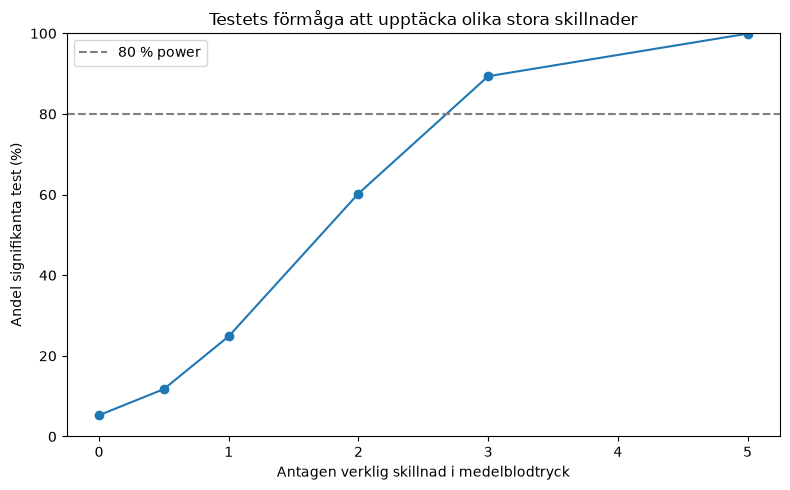

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    power_results["assumed_difference"],
    power_results["rejection_percent"],
    marker="o"
)

plt.axhline(
    80, color="gray", linestyle="--", label="80 % power"
)

plt.title("Testets förmåga att upptäcka olika stora skillnader")
plt.xlabel("Antagen verklig skillnad i medelblodtryck")
plt.ylabel("Andel signifikanta test (%)")
plt.ylim(0, 100)
plt.legend()

plt.tight_layout()
plt.show()

In [17]:
import sys
from importlib.metadata import version

print(f"Python: {sys.version.split()[0]}")

for package in ["numpy", "pandas", "seaborn", "matplotlib", "scipy"]:
    print(f"{package}=={version(package)}")

Python: 3.14.7
numpy==2.5.4
pandas==3.0.6
seaborn==0.13.2
matplotlib==3.11.2
scipy==1.18.1


## Del 2 – Fördjupning och pipeline

### Kodstruktur och återanvändning

Delar av analyskoden från del 1 har flyttats till modulen
`health_analyzer.py`. Modulen innehåller klassen `HealthAnalyzer`,
som sparar en kopia av datasetet och samlar metoder för
beskrivande statistik, visualisering, linjär regression och PCA.

Notebooken använder klassens metoder för beräkningar och vissa
grafer, medan metodförklaringar och resultattolkningar finns kvar
här. Samma metoder kan användas för olika kolumner utan att
hela beräkningskoden behöver upprepas.

Klassen och dess metoder dokumenteras med docstrings.
Dokumentation:
- [Python: moduler](https://docs.python.org/3/tutorial/modules.html)
- [Python: klasser](https://docs.python.org/3/tutorial/classes.html)
- [Python: docstrings](https://docs.python.org/3/tutorial/controlflow.html#documentation-strings)


### Sambandet mellan ålder och systoliskt blodtryck

Ett spridningsdiagram används för att undersöka sambandet
mellan ålder och systoliskt blodtryck inför regressionsanalysen.
Varje punkt representerar en person. Genomskinliga punkter
gör det lättare att se områden där många observationer överlappar.

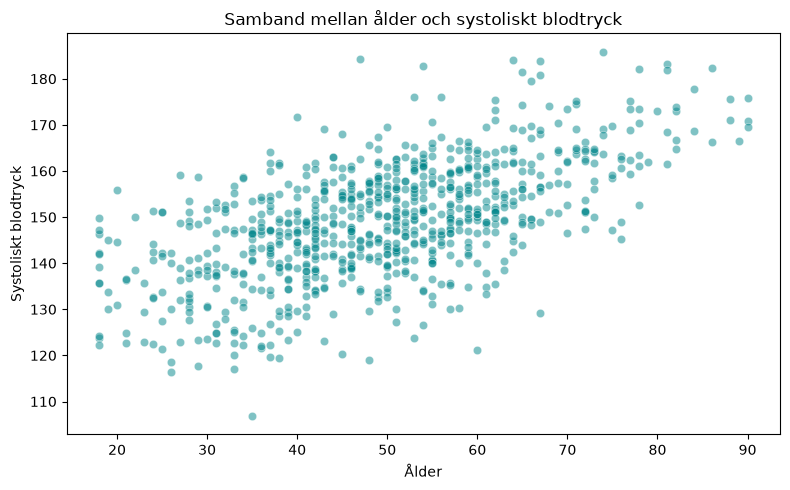

In [18]:
analyzer.plot_scatter(
    x="age",
    y="systolic_bp",
    title="Samband mellan ålder och systoliskt blodtryck",
    xlabel="Ålder",
    ylabel="Systoliskt blodtryck"
)

Spridningsdiagrammet visar ett positivt, ungefär linjärt samband
mellan ålder och systoliskt blodtryck. Äldre personer tenderar
att ha högre blodtryck i datasetet, men variationen är betydande
även bland personer med samma ålder.

En linjär regressionsmodell används därför som en första
beskrivning av sambandet. Grafen visar ett statistiskt samband
och fastställer inte ett orsakssamband. Modellen skattas med minsta kvadratmetoden via NumPys
`linalg.lstsq()`, med en kolumn av ettor för interceptet.

Källor och dokumentation:
- [Python - #38 Linjär Regression  (YouTube)](https://www.youtube.com/watch?v=ZsJ-DbKpD3s)
- [NumPy: numpy.linalg.lstsq](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html)

In [19]:
age_model = analyzer.linear_regression(
    predictors=["age"],
    outcome="systolic_bp"
)

print(f"Antal observationer: {age_model['n']}")
print(f"Intercept: {age_model['intercept']:.2f}")
print(f"Koefficient för ålder: {age_model['coefficients']['age']:.3f}")
print(f"R²: {age_model['r_squared']:.3f}")

Antal observationer: 800
Intercept: 122.68
Koefficient för ålder: 0.536
R²: 0.369


Regressionsmodellen visar ett positivt samband mellan ålder
och systoliskt blodtryck. Ett års högre ålder är förknippat
med cirka 0,536 enheter högre skattat medelblodtryck.

Modellens R² är 0,369, vilket innebär att den förklarar cirka
36,9 procent av variationen i det analyserade datasetet.
Resultatet visar ett samband och ska inte tolkas som en
kausal effekt eller som en förändring som uppmätts inom
samma person över tid.

### Multipel linjär regression med ålder och vikt

Modellen utökas med vikt för att undersöka sambandet mellan
vikt och systoliskt blodtryck när ålder hålls konstant.
Samtidigt skattas sambandet med ålder vid konstant vikt.

Samma metod används som i den enkla regressionen:
minsta kvadratmetoden via `numpy.linalg.lstsq()`.
Designmatrisen innehåller nu en kolumn med ettor för
interceptet samt kolumner för ålder och vikt.

Modellernas R² jämförs för att beskriva anpassningen till
datasetet. R² kan inte minska när en förklarande variabel
läggs till i en sådan modell på samma observationer.
Ett högre R² visar därför inte ensamt bättre
prediktionsförmåga på nya data.

Dokumentation:
- [NumPy: numpy.linalg.lstsq](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html)

In [20]:
age_weight_model = analyzer.linear_regression(
    predictors=["age", "weight"],
    outcome="systolic_bp"
)

print(f"Antal observationer: {age_weight_model['n']}")
print(f"Intercept: {age_weight_model['intercept']:.2f}")

for variable, coefficient in age_weight_model["coefficients"].items():
    print(f"Koefficient för {variable}: {coefficient:.3f}")

print(f"R²: {age_weight_model['r_squared']:.3f}")

Antal observationer: 800
Intercept: 109.50
Koefficient för age: 0.539
Koefficient för weight: 0.178
R²: 0.405


Den multipla regressionen inkluderar ålder och vikt som
förklarande variabler för systoliskt blodtryck.

Vid samma vikt är ett års högre ålder förknippat med cirka
0,539 enheter högre skattat medelblodtryck. Vid samma ålder
är en enhets högre vikt förknippad med cirka 0,178 enheter
högre skattat medelblodtryck.

R² ökar från 0,369 för modellen med enbart ålder till 0,405
när vikt inkluderas. Modellen förklarar därmed cirka
40,5 procent av variationen i datasetet. Ökningen avser
anpassningen till samma data som modellen skattats på;
prediktionsförmågan på nya observationer har inte utvärderats.

Koefficienterna beskriver justerade statistiska samband,
inte fastställda kausala effekter.

### Granskning av modellens residualer

Residualerna ritas mot modellens skattade värden för att
undersöka om tydliga mönster återstår efter anpassningen.

En ungefär jämn spridning kring noll utan tydlig kurvform
stödjer modellens antaganden om linjärt medelvärdessamband
och konstant felvarians. En trattform kan tyda på varierande
felvarians, medan en kurvform kan tyda på att modellen
behöver beskriva ett icke-linjärt samband.

Grafen kan inte ensam bedöma alla modellantaganden,
exempelvis observationernas oberoende.

Residualerna beräknas som observerat minus skattat blodtryck.
Grafen skapas med klassens metod `plot_residuals()`, som använder
Matplotlibs `scatter()` och en horisontell referenslinje vid noll.

Källor och dokumentation:
- [NIST: granskning av modellens residualer](https://www.itl.nist.gov/div898/handbook/pri/section2/pri24.htm)
- [Matplotlib: pyplot.scatter](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html)
- [Matplotlib: pyplot.axhline](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.axhline.html)

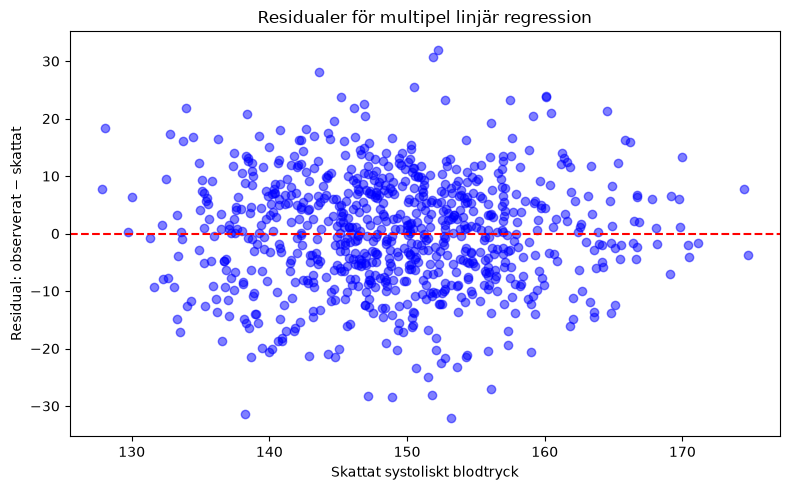

In [21]:
analyzer.plot_residuals(age_weight_model)

Residualerna är ungefär fördelade kring noll utan tydlig
kurvform eller trattform. Grafen visar därmed inga uppenbara
avvikelser från ett linjärt medelvärdessamband eller konstant
felvarians, men den fastställer inte att antagandena är uppfyllda.

Några observationer har stora positiva eller negativa residualer.
Modellen fångar därför inte all individuell variation i blodtryck.
Bedömningen är mer osäker i ytterkanterna, där observationerna
är färre.

### PCA av fem numeriska hälsovariabler

PCA används som ett explorativt komplement till regressionen.
Regressionen behandlar blodtryck som utfall, medan PCA undersöker
gemensamma variationsmönster utan att välja en utfallsvariabel.

Analysen inkluderar ålder, längd, vikt, systoliskt blodtryck och
kolesterol. Identifieraren `id` utesluts eftersom den inte är en
mätvariabel. Sjukdomsstatus används senare för färgläggning,
men påverkar inte beräkningen av komponenterna.

Variablerna standardiseras genom att medelvärdet subtraheras
och resultatet divideras med stickprovets standardavvikelse.
Varje variabel får därmed medelvärde noll och standardavvikelse
ett. Detta förhindrar att skillnader i måttenheter och numerisk
skala styr analysen.

Klassens metod `pca()` använder singularvärdesuppdelning (SVD)
via `numpy.linalg.svd()`. Komponenterna är vinkelräta riktningar
som successivt fångar största möjliga återstående variation.
Standardiseringen görs uttryckligen i vår metod.

Scikit-learns dokumentation används som metodstöd.
Beräkningen genomförs med NumPy, inte med scikit-learn.

Källor och dokumentation:
- [Scikit-learn: Principal component analysis](https://scikit-learn.org/stable/modules/decomposition.html#pca)
- [NumPy: numpy.linalg.svd](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)
- [pandas: Series.std](https://pandas.pydata.org/docs/reference/api/pandas.Series.std.html)

In [22]:
pca_columns = [
    "age", "height", "weight", "systolic_bp", "cholesterol"
]

pca_result = analyzer.pca(pca_columns)

pca_standardized = pca_result["standardized"]

pd.DataFrame({
    "mean": pca_standardized.mean(),
    "std": pca_standardized.std(ddof=1)
}).round(3)

,mean,std
age,-0.0,1.0
height,-0.0,1.0
weight,0.0,1.0
systolic_bp,-0.0,1.0
cholesterol,0.0,1.0


### Förklarad varians per huvudkomponent

Tabellen visar hur stor andel av den totala variationen i de
standardiserade variablerna som varje huvudkomponent fångar.
Den kumulativa andelen visar hur mycket komponenterna
tillsammans fångar när de tas med i ordning.

I metoden `pca()` beräknas komponenternas varians som de
kvadrerade singularvärdena dividerade med n − 1. Varje
komponents varians divideras sedan med summan av samtliga
komponenters varians för att få den förklarade andelen.

Tabellen används för att bedöma hur mycket variation som
behålls när datan visualiseras med endast PC1 och PC2.
Detta avser variationen i samtliga fem standardiserade
variabler, inte enbart i blodtryck.

Källor och dokumentation:
- [Scikit-learn: Principal component analysis](https://scikit-learn.org/stable/modules/decomposition.html#pca)
- [NumPy: numpy.linalg.svd](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)

In [23]:
explained_ratio = pca_result["explained_ratio"]
pca_variance_table = pca_result["variance_table"]

pca_variance_table.round(2)

,component,explained_percent,cumulative_percent
0,PC1,40.91,40.91
1,PC2,26.04,66.96
2,PC3,16.04,83.00
3,PC4,10.82,93.83
4,PC5,6.17,100.00


### Variablernas vikter i huvudkomponenterna

Tabellen visar koefficienterna som används för att bilda
huvudkomponenterna som linjära kombinationer av de
standardiserade variablerna. Vikterna hämtas från de högra
singularvektorerna i SVD-uppdelningen.

Stora absoluta vikter innebär att variabeln bidrar starkt
till komponentens riktning. Vikter med samma tecken anger
bidrag åt samma håll, medan motsatta tecken visar en kontrast
inom komponenten.

En hel komponents tecken kan vändas utan att resultatets
innebörd förändras. Vikterna är komponentkoefficienter,
inte regressionskoefficienter eller direkta mått på
variablernas samband med sjukdom.

Källor och dokumentation:
- [Scikit-learn: Principal component analysis](https://scikit-learn.org/stable/modules/decomposition.html#pca)
- [NumPy: numpy.linalg.svd](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)

In [24]:
pca_weights = pca_result["weights"]

pca_weights.round(3)

,PC1,PC2,PC3,PC4,PC5
age,-0.573,0.280,0.277,-0.143,0.704
height,-0.098,-0.694,0.556,-0.433,-0.111
weight,-0.247,-0.657,-0.495,0.388,0.334
systolic_bp,-0.569,0.059,0.318,0.570,-0.496
cholesterol,-0.526,0.069,-0.517,-0.563,-0.366


De två första huvudkomponenterna fångar tillsammans cirka
67 procent av variationen i de fem standardiserade variablerna.

PC1 domineras av ålder, systoliskt blodtryck och kolesterol,
som har vikter med samma tecken. Komponenten beskriver därför
främst en gemensam variationsriktning för dessa variabler.

PC2 domineras av längd och vikt och kan försiktigt tolkas som
en kroppsstorleksdimension. Ålder bidrar i motsatt riktning
men med en mindre absolut vikt.

Tolkningarna är beskrivande. Komponenterna är matematiska
kombinationer av variablerna, inte fastställda biologiska
mekanismer eller mått på hälsorisk.

### Visualisering av personernas komponentpoäng

Personernas komponentpoäng beräknas i metoden `pca()` genom
att den standardiserade datamatrisen multipliceras med
matrisen av komponentvikter.

Varje punkt i diagrammet representerar en person, placerad
efter sina poäng på PC1 och PC2. Närliggande punkter har
liknande positioner längs dessa två komponenter, men kan
skilja sig längs övriga komponenter.

Axeltexterna anger hur stor andel av den totala variationen
respektive komponent fångar. Diagrammet används för att
utforska övergripande struktur och eventuell gruppering.

Källor och dokumentation:
- [Scikit-learn: Principal component analysis](https://scikit-learn.org/stable/modules/decomposition.html#pca)
- [NumPy: numpy.linalg.svd](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)
- [Matplotlib: pyplot.scatter](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html)

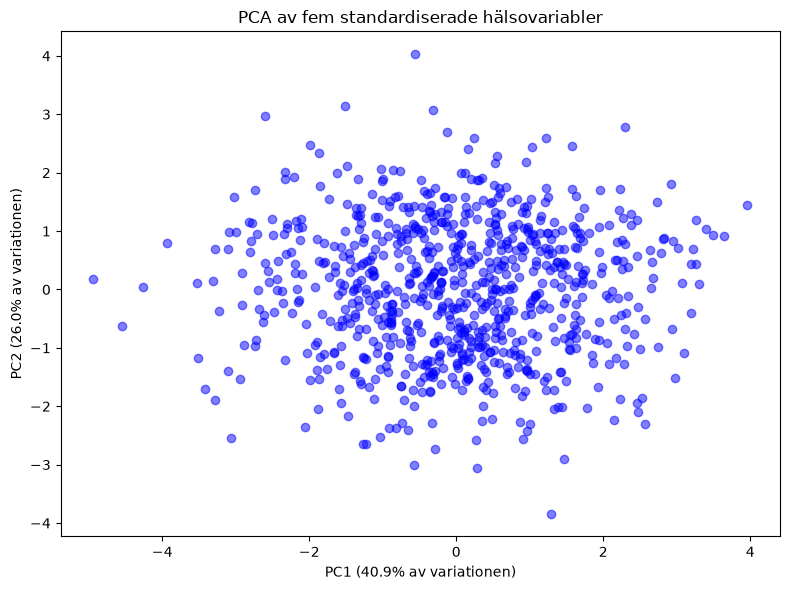

In [27]:
pca_scores = pca_result["scores"]

plt.figure(figsize=(8, 6))

plt.scatter(
    pca_scores["PC1"],
    pca_scores["PC2"],
    color="blue",
    alpha=0.5
)

plt.xlabel(f"PC1 ({explained_ratio[0]:.1%} av variationen)")
plt.ylabel(f"PC2 ({explained_ratio[1]:.1%} av variationen)")
plt.title("PCA av fem standardiserade hälsovariabler")

plt.tight_layout()
plt.show()

PCA-diagrammet visar ett sammanhängande punktmoln utan tydligt
åtskilda grupper i PC1–PC2-planet. Variationen framstår främst
som kontinuerlig.

Utifrån komponentvikterna motsvarar lägre PC1-poäng generellt
högre värden på kombinationen av ålder, blodtryck och kolesterol.
Lägre PC2-poäng motsvarar främst högre värden på kombinationen
av längd och vikt.

De två komponenterna fångar cirka 67 procent av variationen.
Frånvaron av tydliga grupper i denna projektion utesluter
därför inte mönster i övriga komponenter.

### PCA färglagd efter sjukdomsstatus

Samma komponentpoäng som i föregående diagram färgläggs
efter sjukdomsstatus. Statusen kopplas till personerna via
radindex, så att varje punkt får rätt grupptillhörighet.

Sjukdomsstatus ingår inte i PCA-beräkningen och påverkar
därför inte komponenternas riktningar eller punktplaceringarna.
Färgläggningen används enbart för att visuellt undersöka
gruppernas placering och överlappning.

Personer med sjukdom ritas sist för att synas bättre,
eftersom denna grupp är mindre. Diagrammet är explorativt
och utgör varken ett hypotesprövningstest eller en
klassificeringsmodell.

Dokumentation:
- [pandas: DataFrame.loc](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html)
- [pandas: Series.map](https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html)
- [Matplotlib: pyplot.scatter](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html)

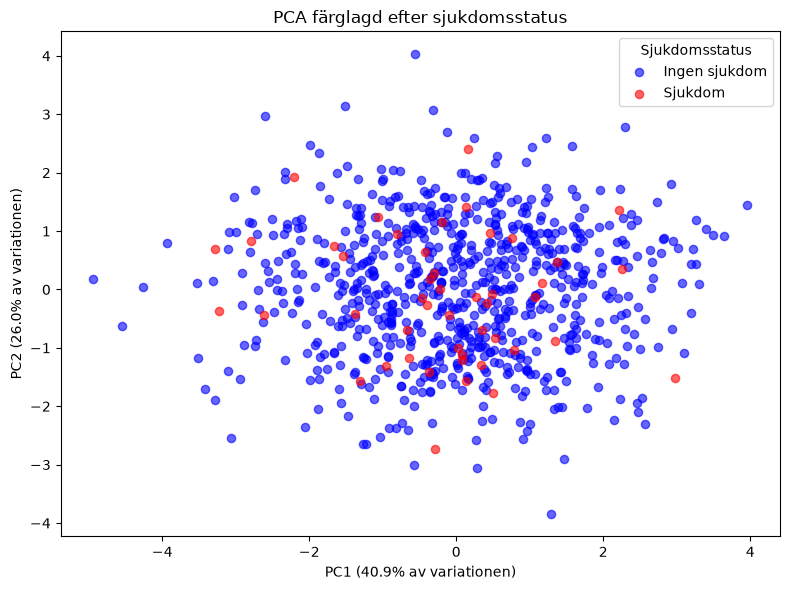

In [29]:
# Koppla sjukdomsstatus till rätt personer via radindex
pca_plot_data = pca_scores.copy()

pca_plot_data["disease_status"] = (
    df.loc[pca_plot_data.index, "disease"]
    .map({0: "Ingen sjukdom", 1: "Sjukdom"})
)

plt.figure(figsize=(8, 6))

# Rita den större gruppen först
for status, color in [
    ("Ingen sjukdom", "blue"),
    ("Sjukdom", "red")
]:
    group = pca_plot_data[
        pca_plot_data["disease_status"] == status
    ]

    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=status,
        color=color,
        alpha=0.6,
        s=35
    )

plt.xlabel(f"PC1 ({explained_ratio[0]:.1%} av variationen)")
plt.ylabel(f"PC2 ({explained_ratio[1]:.1%} av variationen)")
plt.title("PCA färglagd efter sjukdomsstatus")
plt.legend(title="Sjukdomsstatus")

plt.tight_layout()
plt.show()

När PCA-diagrammet färgläggs efter sjukdomsstatus syns stor
överlappning mellan personer med och utan sjukdom. Ingen
tydlig separation framträder i de två första komponenterna.

Detta är en visuell, explorativ bedömning och visar inte
att sjukdom saknar samband med de analyserade variablerna.
PC1 och PC2 fångar cirka 67 procent av variationen, och
sjukdomsstatus användes inte när komponenterna beräknades.
PCA söker riktningar med stor variation, inte riktningar
som bäst skiljer sjukdomsgrupperna åt.

Gruppen med sjukdom är dessutom betydligt mindre:
47 personer jämfört med 753 utan sjukdom.